# Flow Matching

In [28]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Datasets

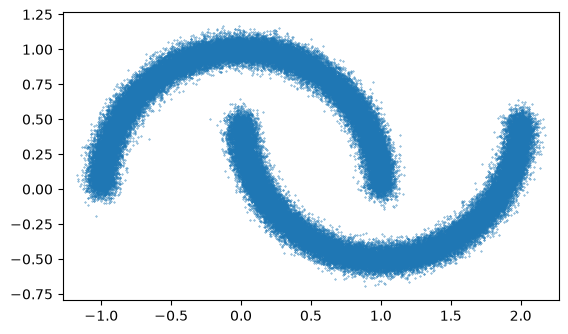

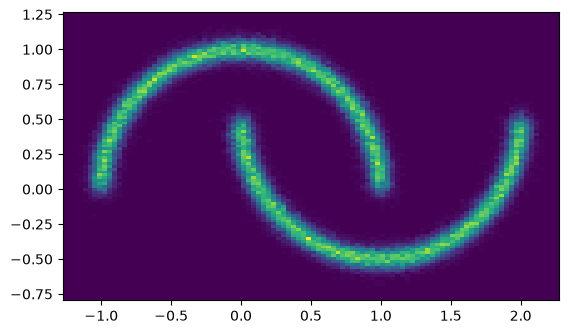

In [29]:
from generative_models.data import MoonsDataset, CirclesDataset, BlobsDataset
import matplotlib.pyplot as plt

dataset = MoonsDataset(n_samples=100000, noise=0.05)
x, y = dataset.x, dataset.y

pad = 0.1
xlim = (x[:, 0].min() - pad, x[:, 0].max() + pad)
ylim = (x[:, 1].min() - pad, x[:, 1].max() + pad)

fig, ax = plt.subplots()
ax.scatter(x[:, 0], x[:, 1], s=0.1)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect(aspect='equal')

fig, ax = plt.subplots()
ax.hist2d(x[:, 0], x[:, 1], bins=100, range=[xlim, ylim])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect(aspect='equal')

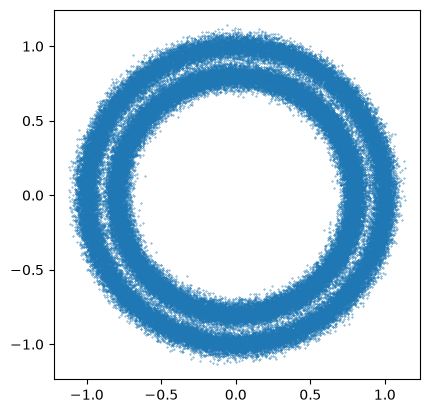

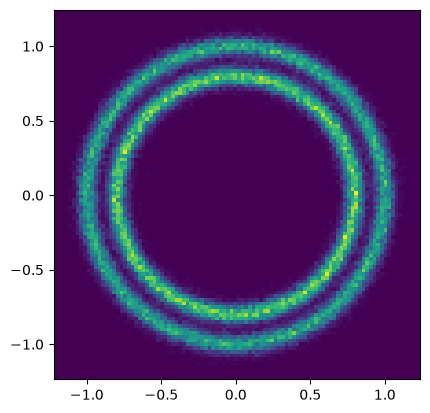

In [30]:
dataset = CirclesDataset(n_samples=100000, noise=0.04)
x, y = dataset.x, dataset.y

pad = 0.1
xlim = (x[:, 0].min() - pad, x[:, 0].max() + pad)
ylim = (x[:, 1].min() - pad, x[:, 1].max() + pad)

fig, ax = plt.subplots()
ax.scatter(x[:, 0], x[:, 1], s=0.1)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect(aspect='equal')

fig, ax = plt.subplots()
ax.hist2d(x[:, 0], x[:, 1], bins=100, range=[xlim, ylim])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect(aspect='equal')

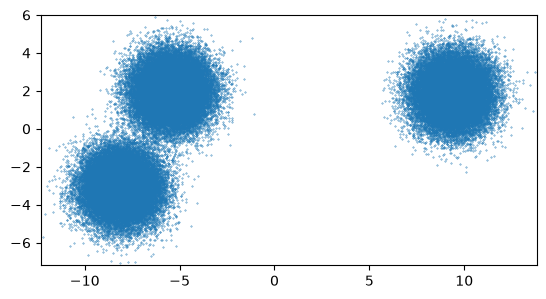

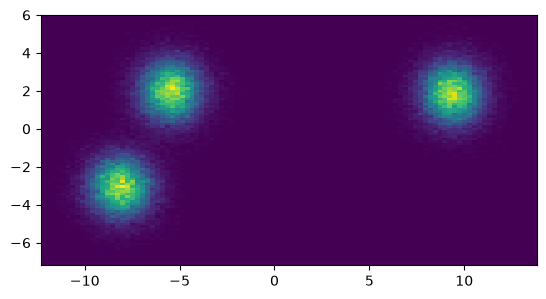

In [31]:
dataset = BlobsDataset(n_samples=100000)
x, y = dataset.x, dataset.y

pad = 0.1
xlim = (x[:, 0].min() - pad, x[:, 0].max() + pad)
ylim = (x[:, 1].min() - pad, x[:, 1].max() + pad)

fig, ax = plt.subplots()
ax.scatter(x[:, 0], x[:, 1], s=0.1)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect(aspect='equal')

fig, ax = plt.subplots()
ax.hist2d(x[:, 0], x[:, 1], bins=100, range=[xlim, ylim])
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_aspect(aspect='equal')

## Flow Matching
### Gaussian OT

In [32]:
from generative_models.trainer import GaussianOTFlowMatchingTrainer
from generative_models.model import FlowMatchingMLP

config = {
    'lr': 1e-3,
    'batch_size': 1000,
    'total_steps': 10000,
    'log': True,
    'project': 'GassianOTFlowMatching',
    'name': 'mlp_lr_1e-3'
}

dataset = MoonsDataset(n_samples=100000, noise=0.05)
model = FlowMatchingMLP(2, [64, 64, 64, 2])
trainer = GaussianOTFlowMatchingTrainer(model, dataset, config)

trainer.train()

loss,█▆▄▄▄▁▄▃▃▃▃▅▂▂▃▄▆▃▄▄▃▂▄▄▂▇▆▆▇▅▄▅▅▅▃▅▃▄▅▃
loss,2.24117


100%|██████████| 10000/10000 [00:30<00:00, 331.47it/s, loss=2.02]


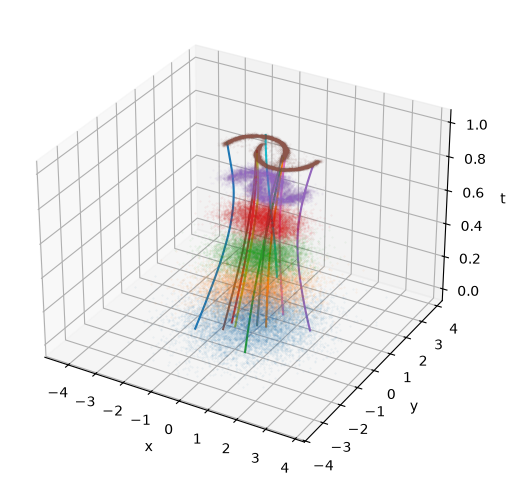

In [33]:
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

x0 = torch.randn((b, 2))
t = torch.linspace(0, 1, l)[None, :].expand(b, l)   # shape (b, l)

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# Draw the simulated flow.
for i in [*range(0, l-1, 20), l-1]:
    ax.scatter(
        x_pred[:, i, 0],
        x_pred[:, i, 1],
        t[:, i],
        s=0.1,
        alpha=0.1,
        depthshade=False
    )

# Draw the simulated trajectories.
for i in range(0, b, b//10):
    ax.plot(
        x_pred[i, :, 0],
        x_pred[i, :, 1],
        t[i, :]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()

Try comparing lr=1e-3 with lr=1e-5.

One step generation.

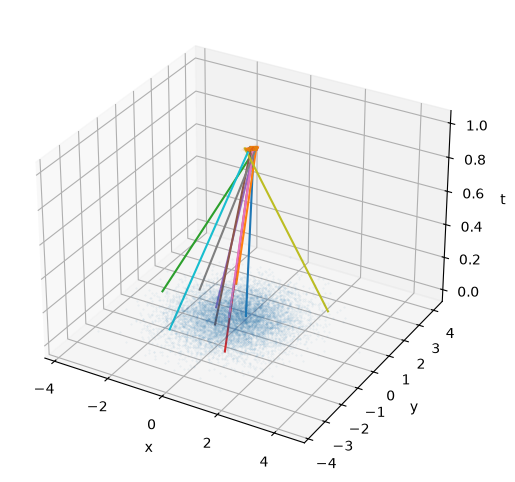

In [34]:
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

x0 = torch.randn((b, 2))
t = torch.zeros((b, 2))
t[:, 1] = 1 # shape (b, l)

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# Draw the simulated flow.
for i in [0, 1]:
    ax.scatter(
        x_pred[:, i, 0],
        x_pred[:, i, 1],
        t[:, i],
        s=0.1,
        alpha=0.1,
        depthshade=False
    )

# Draw the simulated trajectories.
for i in range(0, b, b//10):
    ax.plot(
        x_pred[i, :, 0],
        x_pred[i, :, 1],
        t[i, :]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()

Two step generation.

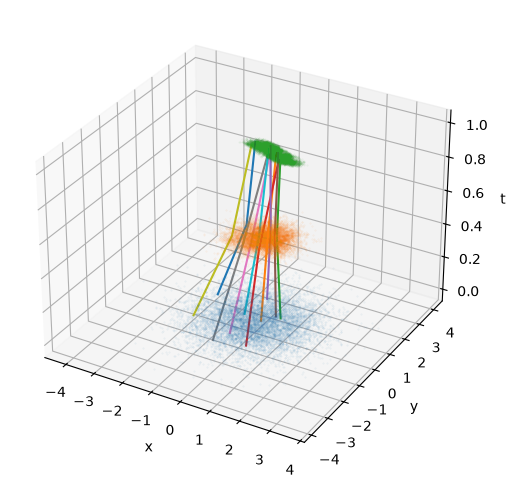

In [35]:
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

x0 = torch.randn((b, 2))
t = torch.zeros((b, 3))
t[:, 1] = 0.5 # shape (b, l)
t[:, 2] = 1

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# Draw the simulated flow.
for i in [0, 1, 2]:
    ax.scatter(
        x_pred[:, i, 0],
        x_pred[:, i, 1],
        t[:, i],
        s=0.1,
        alpha=0.1,
        depthshade=False
    )

# Draw the simulated trajectories.
for i in range(0, b, b//10):
    ax.plot(
        x_pred[i, :, 0],
        x_pred[i, :, 1],
        t[i, :]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()

Wrong initial distribution.

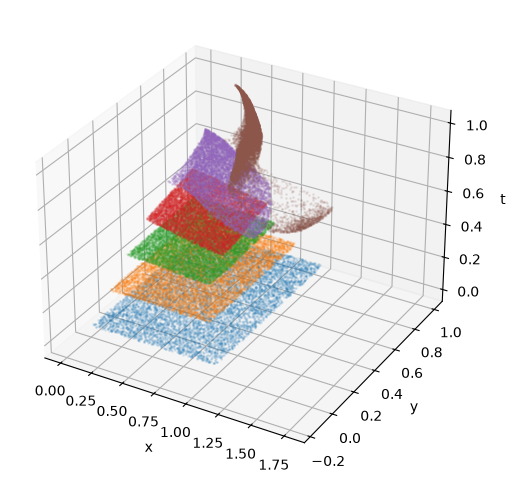

In [36]:
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

x0 = torch.rand((b, 2))
t = torch.linspace(0, 1, l)[None, :].expand(b, l)   # shape (b, l)

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)

x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

for i in [*range(0, l-1, 20), l-1]:
    ax.scatter(
        x_pred[:, i, 0].cpu().detach().numpy(),
        x_pred[:, i, 1].cpu().detach().numpy(),
        t[:, i].cpu(),
        s=1,
        alpha=0.1,
        depthshade=False
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()

Ablations: u(x, t) without t.

In [37]:
class FlowMatchingMLPNoT(FlowMatchingMLP):
    def forward(self, x, t):
        fake_t = torch.zeros_like(t)
        return self.mlp(torch.concat([x, fake_t], dim=1))

In [38]:
from generative_models.trainer import GaussianOTFlowMatchingTrainer
from generative_models.model import FlowMatchingMLP

config = {
    'lr': 1e-3,
    'batch_size': 1000,
    'total_steps': 10000,
    'log': True,
    'project': 'GassianOTFlowMatching',
    'name': 'mlp_lr_1e-3_no_t'
}

dataset = MoonsDataset(n_samples=100000, noise=0.05)
model = FlowMatchingMLPNoT(2, [64, 64, 64, 2])
trainer = GaussianOTFlowMatchingTrainer(model, dataset, config)

trainer.train()

loss,█▅▆▇▅▂▅▇▅▅▇▃▄▂▆▂▅▃▆▄▁▁▃▁▁▄▅▂▁▅▃▅▂▂▃▂▇▆▃▁
loss,2.01539


100%|██████████| 10000/10000 [00:30<00:00, 331.22it/s, loss=2.31]


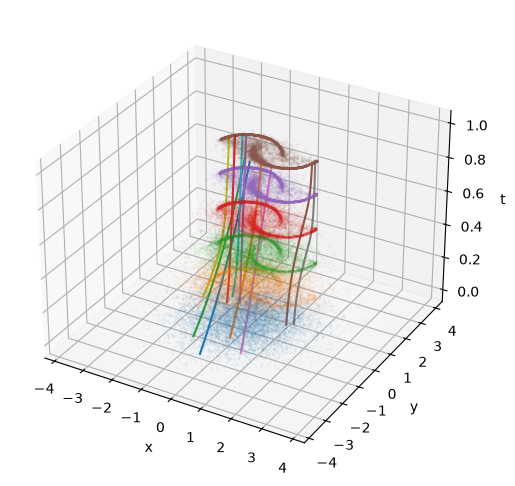

In [39]:
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

x0 = torch.randn((b, 2))
t = torch.linspace(0, 1, l)[None, :].expand(b, l)   # shape (b, l)

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# Draw the simulated flow.
for i in [*range(0, l-1, 20), l-1]:
    ax.scatter(
        x_pred[:, i, 0],
        x_pred[:, i, 1],
        t[:, i],
        s=0.1,
        alpha=0.1,
        depthshade=False
    )

# Draw the simulated trajectories.
for i in range(0, b, b//10):
    ax.plot(
        x_pred[i, :, 0],
        x_pred[i, :, 1],
        t[i, :]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()

One step generation.

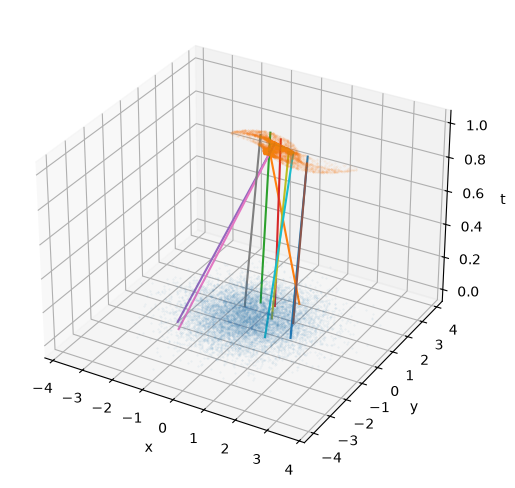

In [46]:
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

x0 = torch.randn((b, 2))
t = torch.zeros((b, 2))
t[:, 1] = 1 # shape (b, l)

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# Draw the simulated flow.
for i in [0, 1]:
    ax.scatter(
        x_pred[:, i, 0],
        x_pred[:, i, 1],
        t[:, i],
        s=0.1,
        alpha=0.1,
        depthshade=False
    )

# Draw the simulated trajectories.
for i in range(0, b, b//10):
    ax.plot(
        x_pred[i, :, 0],
        x_pred[i, :, 1],
        t[i, :]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()